# Conv ResNet on CIFAR-10: train and inspect a run

This notebook is for **analysis**: it reads `history.json`, `summary.json` and `best.pt` from one run
directory and plots what the run did. It can also launch [`train.py`](train.py) first (section 2), which is
convenient from an interactive GPU session, but the tracked runs in `runs/` were all trained by the Slurm
scripts (`train.sbatch`, `pipeline.sbatch`); set `SKIP_TRAINING = True` to analyse one of those. The script
stays the single source of truth for the model, data pipeline and recipe; the notebook only picks the flags.

**On the NYU HPC**, open this through OOD / Jupyter on a **GPU node** (an A100 does the full 100-epoch
run in ~6.5 min; without a GPU use `SMOKE = True` just to check plumbing). Pick a kernel whose Python has
PyTorch, NumPy, Pillow and matplotlib (the project's `.venv` works). The notebook must be run with the
repo as its working directory, so `train.py` and `data/` sit next to it.

Sections:

1. Setup and configuration
2. Train (streams the script's log into the cell)
3. Training curves: loss, accuracy, learning rate, epoch time
4. Local test split: confusion matrix, per-class accuracy, hardest mistakes
5. Kaggle predictions and comparison with earlier runs

## 1. Setup and configuration

In [2]:
import json
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
assert (ROOT / "train.py").exists(), f"run this notebook from the repo root, not {ROOT}"
sys.path.insert(0, str(ROOT))
import train  # model, data loaders and eval helpers from train.py

# Root of the competition data: train_images/ + train_labels.csv, test_images/ + test.csv.
# Point this elsewhere (e.g. a /scratch path on the HPC) if the data is not inside the repo.
DATA_DIR = ROOT / "/scratch/rl3725/deep_learning/project_1/data"
assert (DATA_DIR / "train_labels.csv").exists(), f"no competition data found in {DATA_DIR}"
print("data dir", DATA_DIR)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # same rule as train.py's --device default
print("python", sys.version.split()[0], "| torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cuda":
    print("gpu:", torch.cuda.get_device_name(0))

data dir /scratch/rl3725/deep_learning/project_1/data
python 3.12.16 | torch 2.15.0+cu132 | device cuda
gpu: NVIDIA A100-SXM4-80GB


`DATA_DIR` above is the only path you should need to change on the cluster. Every key in `CONFIG` is a `train.py` flag (`python train.py -h` lists them all). Change `RUN_NAME`
for each experiment so runs do not overwrite each other; tracked runs follow the `baseline_<job id>`
naming from the README.

In [3]:
RUN_NAME = "notebook"      # -> runs/<RUN_NAME>/
SMOKE = False              # True: 1 epoch on 1,000 images, CPU-friendly plumbing check only

# Every key is a train.py flag. This is the 4.7M-parameter recipe; the 5x5 ResNet-20 baseline in the
# README is blocks [3, 3, 3], width 32, kernel 5, epochs 100, patience 20, and the last five keys off.
CONFIG = {
    "blocks": [4, 4, 3],   # basic blocks per stage (4 4 3 -> ResNet-24; 3 3 3 -> ResNet-20)
    "width": 64,           # channels in the first stage (stages: 64, 128, 256)
    "kernel": 3,           # conv kernel size everywhere (5 for the 5x5 baseline)
    "epochs": 200,
    "patience": 0,         # early stopping, 0 = off (run the full cosine schedule)
    "batch": 128,
    "lr": 0.1,
    "wd": 5e-4,
    "warmup": 1.0,         # epochs of linear warmup, then cosine to 0
    "jitter": [0.2, 0.2, 0.2],  # brightness, contrast, saturation; 0 0 0 = off
    "label-smoothing": 0.1,     # 0 = off
    "cutout": 16,               # side of the square hole, 0 = off
    "mix": "cutmix",            # none | mixup | cutmix
    "mix-alpha": 1.0,           # lambda ~ Beta(alpha, alpha)
    "mix-prob": 1.0,            # fraction of batches that are mixed
    "seed": 0,
}

RUN_DIR = ROOT / "runs" / RUN_NAME
cmd = [sys.executable, "-u", str(ROOT / "train.py"), "--data", str(DATA_DIR), "--out", str(RUN_DIR)]
for k, v in CONFIG.items():
    cmd += [f"--{k}"] + [str(x) for x in (v if isinstance(v, list) else [v])]
if SMOKE:
    cmd.append("--smoke")
print(" ".join(cmd))

/ext3/miniforge3/envs/dl/bin/python -u /scratch/rl3725/deep_learning/project_1/train.py --data /scratch/rl3725/deep_learning/project_1/data --out /scratch/rl3725/deep_learning/project_1/runs/notebook --blocks 4 4 3 --width 64 --kernel 3 --epochs 200 --patience 0 --batch 128 --lr 0.1 --wd 0.0005 --warmup 1.0 --jitter 0.2 0.2 0.2 --label-smoothing 0.1 --cutout 16 --mix cutmix --mix-alpha 1.0 --mix-prob 1.0 --seed 0


## 2. Train

The script runs as a subprocess with its stdout streamed into this cell, so you see the same per-epoch
log as a SLURM job would write. The cell blocks until training finishes. Set `SKIP_TRAINING = True`
to just re-plot an existing run directory.

In [4]:
SKIP_TRAINING = False

if SKIP_TRAINING:
    print("skipping training, using existing", RUN_DIR)
else:
    t0 = time.time()
    proc = subprocess.Popen(cmd, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    rc = proc.wait()
    print(f"\nexit code {rc}  ({time.time() - t0:.0f}s wall)")
    assert rc == 0, "train.py failed, see log above"

data: train 40000  val 5000  test 5000  kaggle 2000  (loaded in 0.3s)
model: ResNet-24, 3x3 convs, blocks [4, 4, 3], width 64, 4,697,162 params, device cuda
epoch   1  train 2.1068 / 0.2510  val 1.7405 / 0.3760  lr 0.1000  9.7s
epoch   2  train 1.9230 / 0.3571  val 1.7496 / 0.4100  lr 0.1000  3.8s
epoch   3  train 1.8368 / 0.4032  val 1.1801 / 0.5954  lr 0.1000  3.8s
epoch   4  train 1.7816 / 0.4348  val 1.7744 / 0.4222  lr 0.0999  3.8s
epoch   5  train 1.7360 / 0.4568  val 1.5982 / 0.4690  lr 0.0999  3.8s
epoch   6  train 1.7114 / 0.4720  val 1.0815 / 0.6410  lr 0.0998  3.8s
epoch   7  train 1.7011 / 0.4778  val 1.0040 / 0.6716  lr 0.0998  3.8s
epoch   8  train 1.6771 / 0.4880  val 1.0428 / 0.6638  lr 0.0997  3.8s
epoch   9  train 1.6452 / 0.5052  val 0.9710 / 0.6888  lr 0.0996  3.8s
epoch  10  train 1.6216 / 0.5190  val 0.9008 / 0.7244  lr 0.0995  3.8s
epoch  11  train 1.6200 / 0.5171  val 0.8852 / 0.7118  lr 0.0994  3.8s
epoch  12  train 1.5924 / 0.5332  val 0.8969 / 0.7208  lr 0.09

## 3. Training curves

In [5]:
summary = json.loads((RUN_DIR / "summary.json").read_text())
history = json.loads((RUN_DIR / "history.json").read_text())

print(f"ResNet-{summary['depth']}  {summary['params']:,} params  "
      f"kernel {summary['args']['kernel']}x{summary['args']['kernel']}  blocks {summary['args']['blocks']}")
print(f"epochs run     {summary.get('epochs_run', len(history))}{'  (stopped early)' if summary.get('stopped_early') else ''}")
print(f"best epoch     {summary['best_epoch']}")
print(f"best val acc   {summary['best_val_acc']:.4f}")
print(f"local test acc {summary['test_acc']:.4f}   (scored once with best.pt; do not tune on it)")
print(f"train time     {summary['train_seconds']:.0f}s")

ResNet-24  4,697,162 params  kernel 3x3  blocks [4, 4, 3]
epochs run     200
best epoch     194
best val acc   0.9666
local test acc 0.9650   (scored once with best.pt; do not tune on it)
train time     766s


In [6]:
# Required by the project rules: a clear printout of the architecture, the trainable-parameter count
# (checked against the 5M limit) and the final test accuracy. Lives in model_summary.py, not here.
import model_summary
card = model_summary.report(run=RUN_DIR)

ResNet-24: 3x3 convs, blocks [4, 4, 3], stage widths [64, 128, 256], input [3, 32, 32]
layer     description                                                   output                  params
------------------------------------------------------------------------------------------------------
stem      stem: Conv 3x3 3->64 + BN + ReLU                              [1, 64, 32, 32]          1,856
layers.0  BasicBlock 3x3: 64->64, stride 1, shortcut identity           [1, 64, 32, 32]         73,984
layers.1  BasicBlock 3x3: 64->64, stride 1, shortcut identity           [1, 64, 32, 32]         73,984
layers.2  BasicBlock 3x3: 64->64, stride 1, shortcut identity           [1, 64, 32, 32]         73,984
layers.3  BasicBlock 3x3: 64->64, stride 1, shortcut identity           [1, 64, 32, 32]         73,984
layers.4  BasicBlock 3x3: 64->128, stride 2, shortcut 1x1 projection    [1, 128, 16, 16]       230,144
layers.5  BasicBlock 3x3: 128->128, stride 1, shortcut identity         [1, 128, 16, 16] 

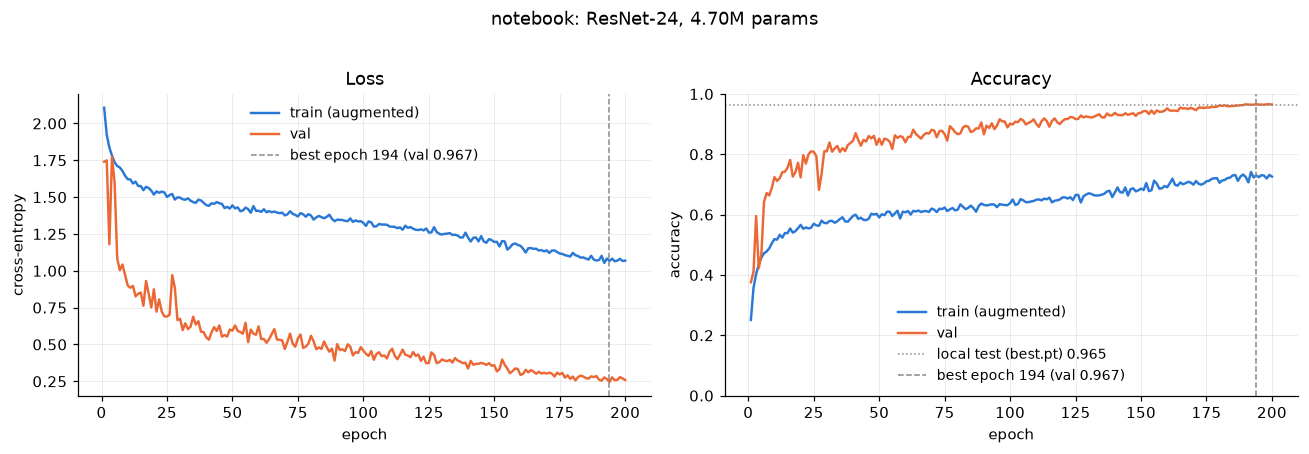

In [7]:
# Shared plot style: two series (train = blue, val = orange), recessive grid, best epoch as a gray marker.
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.6, "lines.linewidth": 1.6, "figure.dpi": 110})

ep = np.array([h["epoch"] for h in history])
col = lambda k: np.array([h[k] for h in history])
best_ep = summary["best_epoch"]
mk = dict(marker="o", ms=3) if len(ep) <= 25 else {}   # short runs would otherwise be invisible

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ep, col("train_loss"), color=BLUE, label="train (augmented)", **mk)
a1.plot(ep, col("val_loss"), color=ORANGE, label="val", **mk)
a1.set(xlabel="epoch", ylabel="cross-entropy", title="Loss")

a2.plot(ep, col("train_acc"), color=BLUE, label="train (augmented)", **mk)
a2.plot(ep, col("val_acc"), color=ORANGE, label="val", **mk)
a2.axhline(summary["test_acc"], color=GRAY, lw=1, ls=":", label=f"local test (best.pt) {summary['test_acc']:.3f}")
a2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy", ylim=(0, 1))
for a in (a1, a2):
    a.axvline(best_ep, color=GRAY, lw=1, ls="--", label=f"best epoch {best_ep} (val {summary['best_val_acc']:.3f})")
    a.legend(frameon=False, fontsize=9)
fig.suptitle(f"{RUN_NAME}: ResNet-{summary['depth']}, {summary['params'] / 1e6:.2f}M params", y=1.02)
fig.tight_layout()
plt.show()

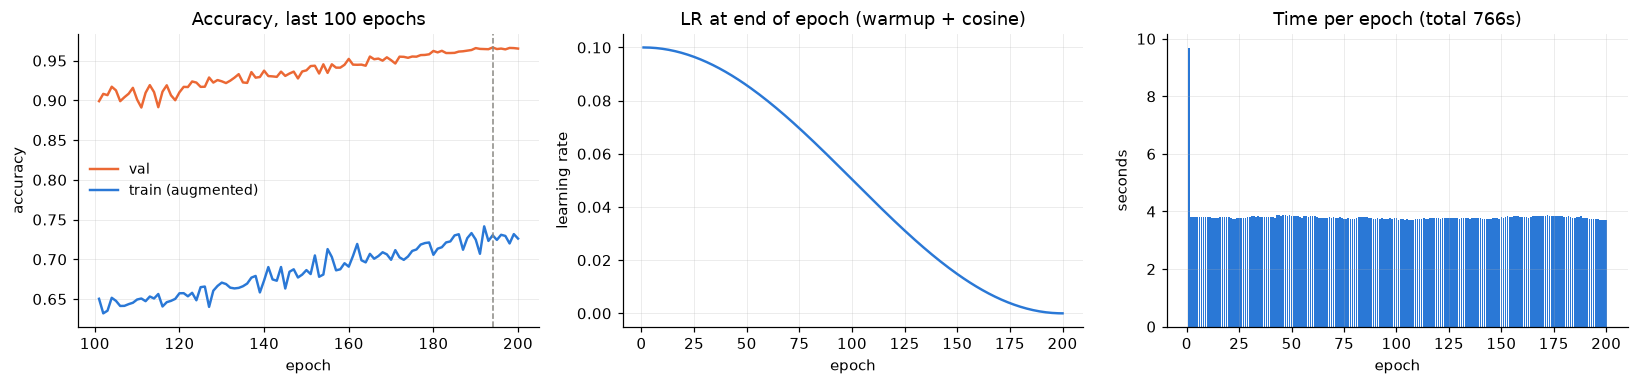

In [8]:
# Zoomed view of the last part of training plus the schedule and the cost per epoch.
tail = max(1, len(ep) // 2)
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 3.6))

a1.plot(ep[-tail:], col("val_acc")[-tail:], color=ORANGE, label="val", **mk)
a1.plot(ep[-tail:], col("train_acc")[-tail:], color=BLUE, label="train (augmented)", **mk)
a1.axvline(best_ep, color=GRAY, lw=1, ls="--")
a1.set(xlabel="epoch", ylabel="accuracy", title=f"Accuracy, last {tail} epochs")
a1.legend(frameon=False, fontsize=9)

a2.plot(ep, col("lr"), color=BLUE, **mk)
a2.set(xlabel="epoch", ylabel="learning rate", title="LR at end of epoch (warmup + cosine)")

a3.bar(ep, col("seconds"), color=BLUE, width=0.8)
a3.set(xlabel="epoch", ylabel="seconds", title=f"Time per epoch (total {summary['train_seconds']:.0f}s)")
fig.tight_layout()
plt.show()

## 4. Local test split: where does the model fail?

`train.py` scores the 5,000-image local test split exactly once. This section reloads `best.pt` and
rebuilds the same split from the run's saved args (same seed and fractions), so the per-class view below
is a *diagnostic* of that single evaluation, not a second tuning signal. Do not pick hyperparameters
from it.

In [9]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
args = summary["args"]
dev = torch.device(DEVICE)

ckpt = torch.load(RUN_DIR / "best.pt", map_location=dev)
model = train.ResNet(tuple(args["blocks"]), args["width"], args["kernel"]).to(dev)
model.load_state_dict(ckpt["model"])
mean, std = ckpt["mean"].to(dev), ckpt["std"].to(dev)

x_all, y_all, x_kaggle, kaggle_ids = train.load_images(DATA_DIR, DATA_DIR / "cache.npz")
_, _, te = train.stratified_split(y_all, args["val_frac"], args["test_frac"], args["seed"])
if args["smoke"]:
    te = te[:200]
x_test_u8 = x_all[te]                                    # uint8 NHWC, for showing images
x_test = (torch.from_numpy(x_test_u8).to(dev).permute(0, 3, 1, 2).float().div_(255) - mean) / std
y_test = torch.from_numpy(y_all[te]).to(dev)

amp = dev.type == "cuda"
test_loss, test_acc = train.evaluate(model, x_test, y_test, 1000, amp)
assert abs(test_acc - summary["test_acc"]) < 1e-6, (test_acc, summary["test_acc"])  # same split, same number
pred = train.predict(model, x_test, 1000, amp).cpu().numpy()
true = y_all[te]
print(f"local test: {len(te)} images, acc {test_acc:.4f}, loss {test_loss:.4f} (matches summary.json)")

local test: 5000 images, acc 0.9650, loss 0.2407 (matches summary.json)


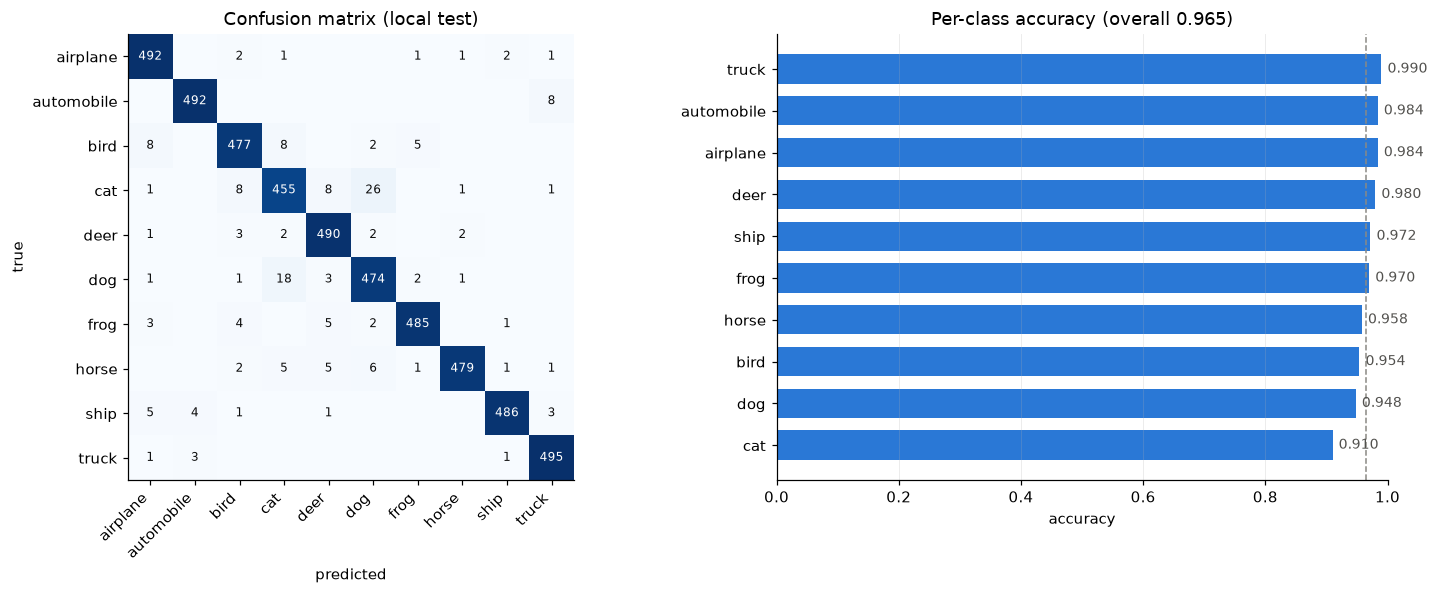

most common confusions (true -> predicted):
         cat -> dog          26
         dog -> cat          18
         cat -> bird          8
         cat -> deer          8
        bird -> cat           8
        bird -> airplane      8


In [10]:
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (true, pred), 1)
per_class = cm.diagonal() / cm.sum(1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.25, 1]})
im = a1.imshow(cm, cmap="Blues", vmin=0)
a1.set(xticks=range(10), yticks=range(10), xlabel="predicted", ylabel="true", title="Confusion matrix (local test)")
a1.set_xticklabels(CLASSES, rotation=45, ha="right"); a1.set_yticklabels(CLASSES)
a1.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            a1.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")

order = np.argsort(per_class)
a2.barh([CLASSES[i] for i in order], per_class[order], color=BLUE, height=0.7)
a2.axvline(test_acc, color=GRAY, lw=1, ls="--")
a2.set(xlim=(0, 1), xlabel="accuracy", title=f"Per-class accuracy (overall {test_acc:.3f})")
for k, i in enumerate(order):
    a2.text(per_class[i] + 0.01, k, f"{per_class[i]:.3f}", va="center", fontsize=9, color="#52514e")
a2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off, axis=None)[::-1][:6], off.shape))[0]
print("most common confusions (true -> predicted):")
for i, j in top:
    print(f"  {CLASSES[i]:>10} -> {CLASSES[j]:<10} {off[i, j]:4d}")

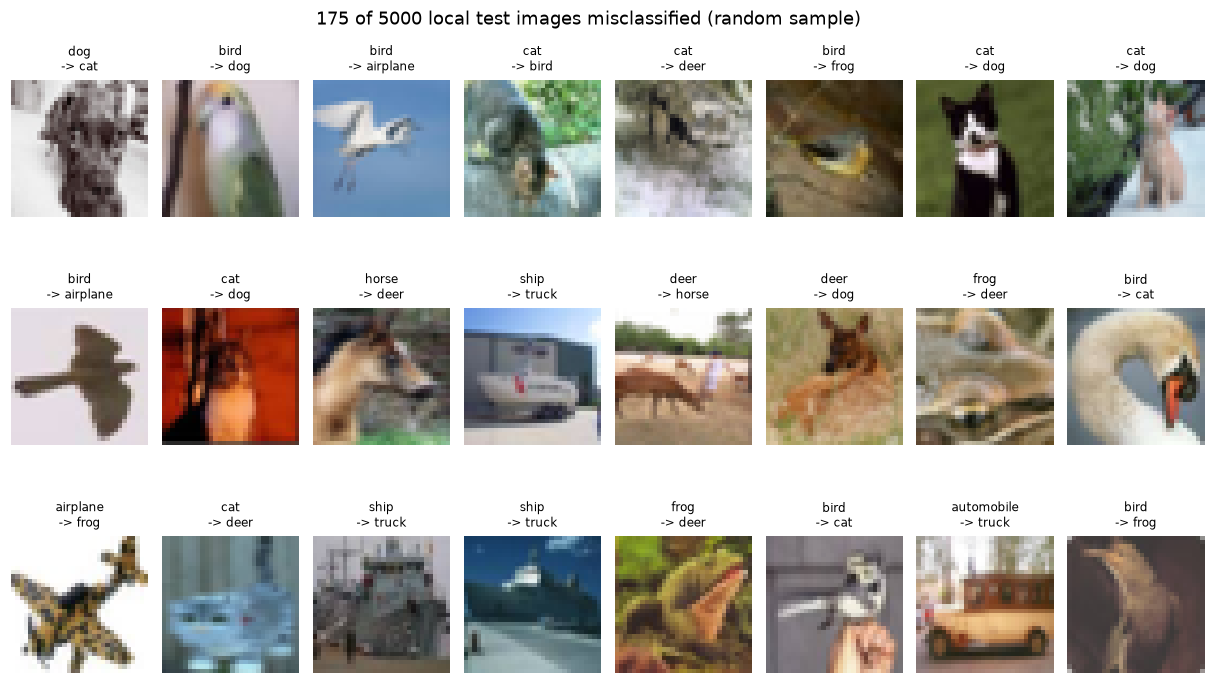

In [11]:
# A grid of misclassified test images, so the failure modes above have faces.
wrong = np.flatnonzero(pred != true)
rng = np.random.default_rng(0)
show = rng.choice(wrong, size=min(24, len(wrong)), replace=False)
fig, axes = plt.subplots(3, 8, figsize=(14, 7))
for a, i in zip(axes.flat, show):
    a.imshow(x_test_u8[i]); a.set_title(f"{CLASSES[true[i]]}\n-> {CLASSES[pred[i]]}", fontsize=8)
for a in axes.flat:
    a.axis("off")
fig.suptitle(f"{len(wrong)} of {len(true)} local test images misclassified (random sample)")
fig.subplots_adjust(hspace=0.5, wspace=0.1, top=0.9)
plt.show()

## 5. Kaggle predictions and comparison with earlier runs

`submission.csv` in the run directory is what you upload. The Kaggle test set is unlabeled, so the only
sanity check is the predicted class distribution: with 2,000 images it should be roughly 200 per class.

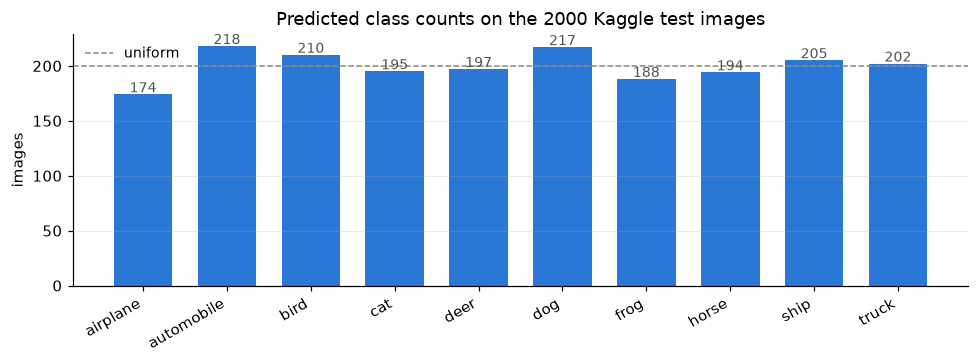

submission: /scratch/rl3725/deep_learning/project_1/runs/notebook/submission.csv


In [12]:
counts = np.array(summary["kaggle_pred_counts"])
fig, a = plt.subplots(figsize=(9, 3.4))
a.bar(CLASSES, counts, color=BLUE, width=0.7)
a.axhline(counts.sum() / 10, color=GRAY, lw=1, ls="--", label="uniform")
for i, c in enumerate(counts):
    a.text(i, c + 2, str(c), ha="center", fontsize=9, color="#52514e")
a.set(ylabel="images", title=f"Predicted class counts on the {counts.sum()} Kaggle test images")
a.grid(axis="x", visible=False); a.legend(frameon=False, fontsize=9)
plt.setp(a.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
plt.show()
print("submission:", RUN_DIR / "submission.csv")

run                    depth     params  epochs  best     val    test        jitter    time
notebook                  24  4,697,162     200   194  0.9666  0.9650   0.2/0.2/0.2    766s


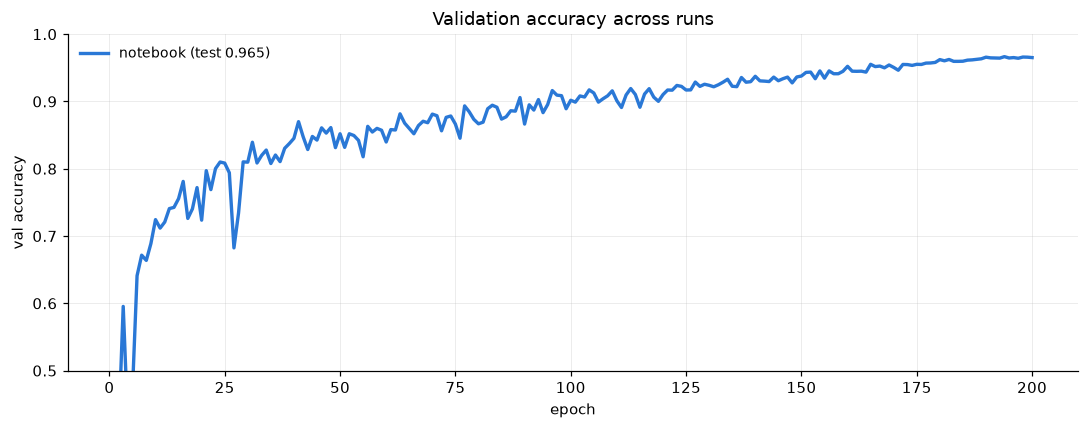

In [13]:
# Every finished run under runs/ (has summary.json + history.json), except smoke runs, which are plumbing checks.
runs = {}
for d in sorted((ROOT / "runs").iterdir()):
    if (d / "summary.json").exists() and (d / "history.json").exists():
        s = json.loads((d / "summary.json").read_text())
        if not s["args"].get("smoke"):
            runs[d.name] = (s, json.loads((d / "history.json").read_text()))

print(f"{'run':<22}{'depth':>6}{'params':>11}{'epochs':>8}{'best':>6}{'val':>8}{'test':>8}{'jitter':>14}{'time':>8}")
for name, (s, h) in runs.items():
    j = s["args"].get("jitter", [0, 0, 0])   # older runs predate the jitter and epochs_run fields
    print(f"{name:<22}{s['depth']:>6}{s['params']:>11,}{s.get('epochs_run', len(h)):>8}{s['best_epoch']:>6}"
          f"{s['best_val_acc']:>8.4f}{s['test_acc']:>8.4f}{'/'.join(f'{x:g}' for x in j):>14}{s['train_seconds']:>7.0f}s")

# Val accuracy per epoch, one line per run; fixed slot order from the dataviz palette (max 8 runs).
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
fig, a = plt.subplots(figsize=(10, 4))
for (name, (s, h)), c in zip(list(runs.items())[-8:], PALETTE):
    a.plot([x["epoch"] for x in h], [x["val_acc"] for x in h], color=c, label=f"{name} (test {s['test_acc']:.3f})",
           lw=2.2 if name == RUN_NAME else 1.4)
a.set(xlabel="epoch", ylabel="val accuracy", title="Validation accuracy across runs", ylim=(0.5, 1))
a.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()